# Classification with Neural Networks - Case Study

Let's consider an example of classification problem solved by using Neural Networks.

## Dataset Description

### Breast cancer Wisconsin (diagnostic) dataset
--------------------------------------------

**Data Set Characteristics:**

    :Number of Instances: 569

    :Number of Attributes: 30 numeric, predictive attributes and the class

    :Attribute Information:
        - radius (mean of distances from center to points on the perimeter)
        - texture (standard deviation of gray-scale values)
        - perimeter
        - area
        - smoothness (local variation in radius lengths)
        - compactness (perimeter^2 / area - 1.0)
        - concavity (severity of concave portions of the contour)
        - concave points (number of concave portions of the contour)
        - symmetry 
        - fractal dimension ("coastline approximation" - 1)

        The mean, standard error, and "worst" or largest (mean of the three
        largest values) of these features were computed for each image,
        resulting in 30 features.  For instance, field 3 is Mean Radius, field
        13 is Radius SE, field 23 is Worst Radius.

        - class:
                - WDBC-Malignant
                - WDBC-Benign

    :Summary Statistics:

    ===================================== ====== ======
                                           Min    Max
    ===================================== ====== ======
    radius (mean):                        6.981  28.11
    texture (mean):                       9.71   39.28
    perimeter (mean):                     43.79  188.5
    area (mean):                          143.5  2501.0
    smoothness (mean):                    0.053  0.163
    compactness (mean):                   0.019  0.345
    concavity (mean):                     0.0    0.427
    concave points (mean):                0.0    0.201
    symmetry (mean):                      0.106  0.304
    fractal dimension (mean):             0.05   0.097
    radius (standard error):              0.112  2.873
    texture (standard error):             0.36   4.885
    perimeter (standard error):           0.757  21.98
    area (standard error):                6.802  542.2
    smoothness (standard error):          0.002  0.031
    compactness (standard error):         0.002  0.135
    concavity (standard error):           0.0    0.396
    concave points (standard error):      0.0    0.053
    symmetry (standard error):            0.008  0.079
    fractal dimension (standard error):   0.001  0.03
    radius (worst):                       7.93   36.04
    texture (worst):                      12.02  49.54
    perimeter (worst):                    50.41  251.2
    area (worst):                         185.2  4254.0
    smoothness (worst):                   0.071  0.223
    compactness (worst):                  0.027  1.058
    concavity (worst):                    0.0    1.252
    concave points (worst):               0.0    0.291
    symmetry (worst):                     0.156  0.664
    fractal dimension (worst):            0.055  0.208
    ===================================== ====== ======

    :Missing Attribute Values: None

    :Class Distribution: 212 - Malignant, 357 - Benign

    :Creator:  Dr. William H. Wolberg, W. Nick Street, Olvi L. Mangasarian

    :Donor: Nick Street

    :Date: November, 1995

This is a copy of UCI ML Breast Cancer Wisconsin (Diagnostic) datasets.
https://goo.gl/U2Uwz2

Features are computed from a digitized image of a fine needle
aspirate (FNA) of a breast mass.  They describe
characteristics of the cell nuclei present in the image.

Separating plane described above was obtained using
Multisurface Method-Tree (MSM-T) [K. P. Bennett, "Decision Tree
Construction Via Linear Programming." Proceedings of the 4th
Midwest Artificial Intelligence and Cognitive Science Society,
pp. 97-101, 1992], a classification method which uses linear
programming to construct a decision tree.  Relevant features
were selected using an exhaustive search in the space of 1-4
features and 1-3 separating planes.

The actual linear program used to obtain the separating plane
in the 3-dimensional space is that described in:
[K. P. Bennett and O. L. Mangasarian: "Robust Linear
Programming Discrimination of Two Linearly Inseparable Sets",
Optimization Methods and Software 1, 1992, 23-34].

This database is also available through the UW CS ftp server:

ftp ftp.cs.wisc.edu
cd math-prog/cpo-dataset/machine-learn/WDBC/

.. topic:: References

   - W.N. Street, W.H. Wolberg and O.L. Mangasarian. Nuclear feature extraction 
     for breast tumor diagnosis. IS&T/SPIE 1993 International Symposium on 
     Electronic Imaging: Science and Technology, volume 1905, pages 861-870,
     San Jose, CA, 1993.
   - O.L. Mangasarian, W.N. Street and W.H. Wolberg. Breast cancer diagnosis and 
     prognosis via linear programming. Operations Research, 43(4), pages 570-577, 
     July-August 1995.
   - W.H. Wolberg, W.N. Street, and O.L. Mangasarian. Machine learning techniques
     to diagnose breast cancer from fine-needle aspirates. Cancer Letters 77 (1994) 
     163-171.

## Import Data Analysis and Visualization Libraries

In [1]:
%pip install numpy pandas matplotlib seaborn openpyxl
%pip install ipywidgets

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

%matplotlib inline

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


## Import Dataset

In [2]:
df = pd.read_csv('cancer_classification.csv')          # Import Dataset from .csv file
df.rename(columns={"benign_0__mal_1" : "benign_1__mal_0"}, inplace = True)          # Rename column
df.head()                                              # Show header

/tmp/ipykernel_39069/3614546604.py:2: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns={"benign_0__mal_1" : "benign_1__mal_0"}, inplace = True)          # Rename column


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,benign_1__mal_0
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         569 non-null

In [4]:
df.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


## Exploratory Data Analysis

<Axes: >

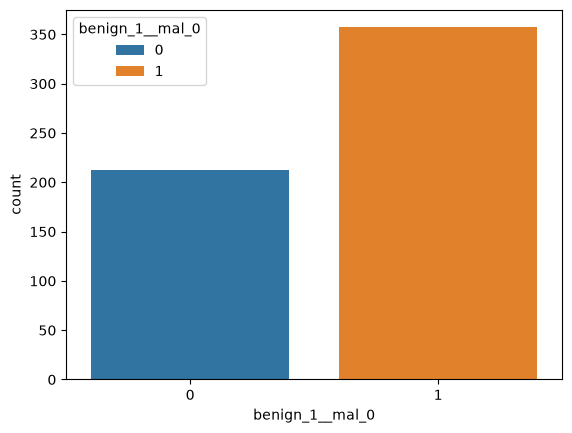

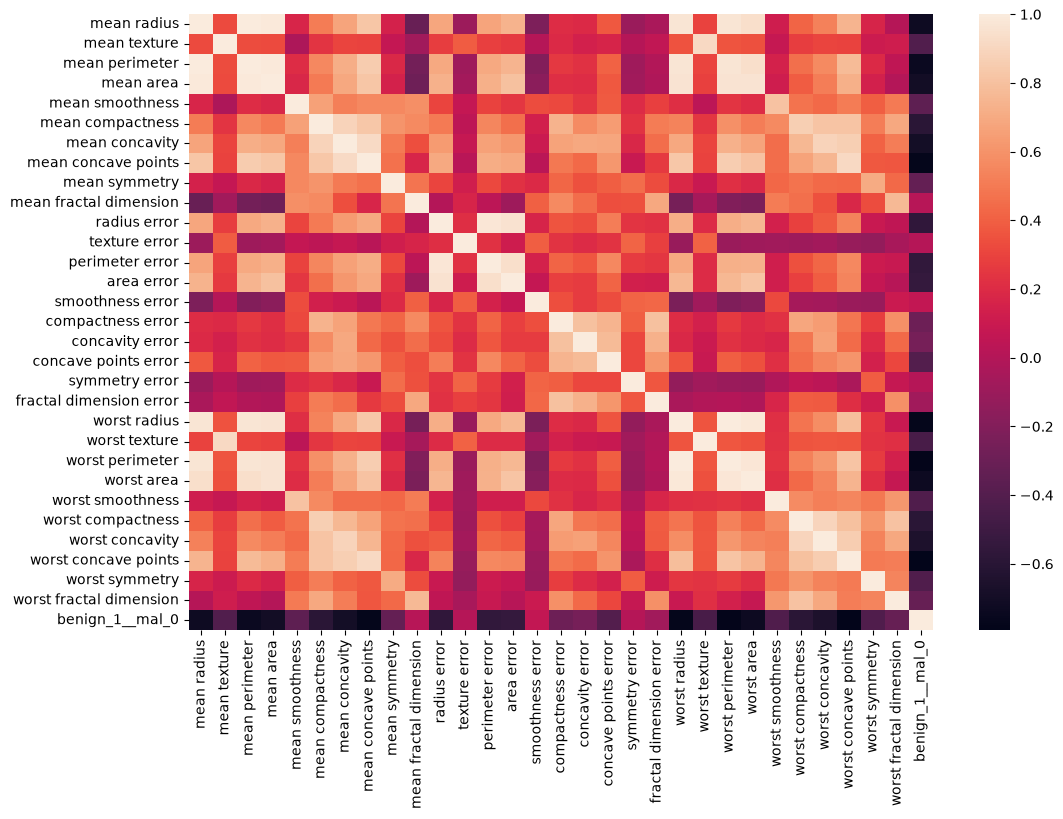

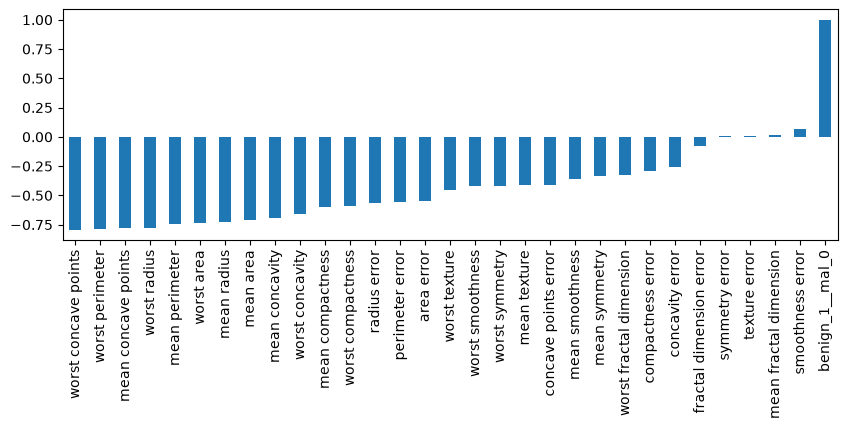

In [5]:
# Plot number of benign vs malignant
sns.countplot(x='benign_1__mal_0',data=df,hue='benign_1__mal_0')

# Plot correlation heatmap
plt.figure(figsize=(12,8))                                 
sns.heatmap(df.corr())                    

# Reorder correlation values for easier inspection
df.corr()['benign_1__mal_0'].sort_values(ascending = False)

# Plot these values
plt.figure(figsize=(10,3))                                        # Create a figure object with a specified figure size
df.corr()['benign_1__mal_0'].sort_values().plot(kind='bar')       # Barplot for the sorted correlation coefficients

## Train/Test Set Split

In [6]:
from sklearn.model_selection import train_test_split            # Import train_test_split function from Scikit-Learn

# Features
X = df.drop('benign_1__mal_0',axis=1).values

# Target Variable
y = df['benign_1__mal_0'].values

# Perform split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=101)         # Train-Test Split
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(426, 30) (143, 30) (426,) (143,)


## Data Pre-Processing

Use StandardScaler() to perform input centering and input normalization.

Notice that it is sufficient to standardize just input features, while it is not necessary to standardize the target variable.

In [7]:
from sklearn.preprocessing import StandardScaler

# Train scaler
scaler = StandardScaler()
scaler.fit(X_train)

# Apply scaling
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

## Neural Network Definition - TensorFlow & Keras

## Creating NN Model

In [8]:
import tensorflow as tf

from tensorflow.keras.models import Sequential                         # Import Sequential() to instatiate a Feed-forward NN object
from tensorflow.keras.layers import Dense                              # Import Dense() to instatiate fully-connected layer objects

I0000 00:00:1793454233.753442   39069 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793454233.800236   39069 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793454235.310074   39069 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793454239.209874   39069 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

In [9]:
# Generate model
model = Sequential()
model.add(Dense(units=30,activation='relu'))
model.add(Dense(units=15,activation='relu'))

# Final output node for prediction
model.add(Dense(units=1, activation='sigmoid'))                         # In the output layer we just have one neuron since the target is a single variable (class)
 
# For a binary classification problem
model.compile(loss='binary_crossentropy', optimizer='adam')             # Optimizer determines the way in which you approach gradient descent (alternative: ADAM)

E0000 00:00:1793454240.266036   39069 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



### Choosing suitable Loss functions and Evaluation Metrics

Keep in mind what kind of problem you are trying to solve:

    # For a multi-class classification problem
    model.compile(optimizer='rmsprop',
                  loss='categorical_crossentropy',
                  metrics='accuracy')

    # For a binary classification problem
    model.compile(optimizer='rmsprop',
                  loss='binary_crossentropy',
                  metrics='accuracy')

    # For a mean squared error regression problem
    model.compile(optimizer='rmsprop',
                  loss='mse')

## Training the Model 

### Example One

In [ ]:
model.fit(x=X_train, y=y_train, epochs=1000, validation_data=(X_test, y_test), verbose=1)
# overfitting because errors are different

Epoch 1/1000
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - loss: 0.6887 - val_loss: 0.5331
Epoch 2/1000
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.4493 - val_loss: 0.3716
Epoch 3/1000
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.3048 - val_loss: 0.2679
Epoch 4/1000
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.2179 - val_loss: 0.2029
Epoch 5/1000
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.1677 - val_loss: 0.1639
Epoch 6/1000
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.1384 - val_loss: 0.1398
Epoch 7/1000
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.1196 - val_loss: 0.1240
Epoch 8/1000
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.1066 - val_loss: 0.1131
Epoch 9/1000
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0971 - val_loss: 0.1048
Epoch 10/1000
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0896 - val_loss: 0.0985
Epoch 11/1000
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0835 - val_loss: 0.0934
Epoch 12/1000
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/s

In [11]:
# Get information about the model
model.summary()

# Save Training and Validation Loss in a Pandas DataFrame
model_loss = pd.DataFrame(model.history.history)    
model_loss.head()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (32, 30)               │           930 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (32, 15)               │           465 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (32, 1)                │            16 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,235 (16.55 KB)

 Trainable params: 1,411 (5.51 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,824 (11.04 KB)

,loss,val_loss
0,0.688664,0.533090
1,0.449340,0.371635
2,0.304793,0.267862
3,0.217865,0.202885
4,0.167743,0.163855


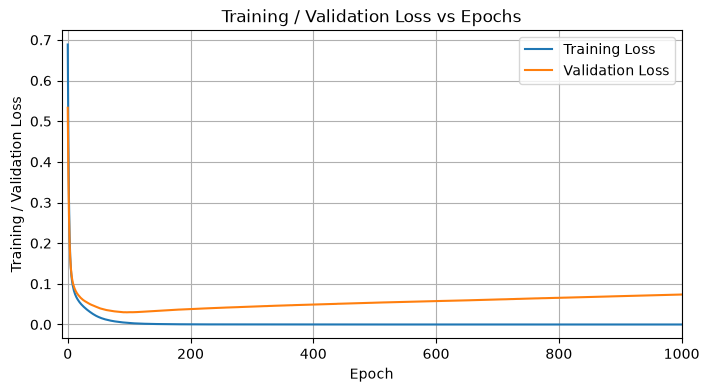

In [12]:
# Plot Training / Validation Loss vs Epochs
plt.figure(figsize = (8, 4))

plt.plot(range(len(model_loss)), model_loss['loss'], label = 'Training Loss')
plt.plot(range(len(model_loss)), model_loss['val_loss'], label = 'Validation Loss')

plt.xlim([-10, len(model_loss)])
plt.xlabel('Epoch')
plt.ylabel('Training / Validation Loss')
plt.title('Training / Validation Loss vs Epochs')
plt.legend()
plt.grid()

Choosing too many epochs and overfitting!

## Example Two: Early Stopping

We obviously trained too much! Let's use early stopping to track the val_loss and stop training once it begins increasing too much!

In [13]:
# Train again a new model
model = Sequential()
model.add(Dense(units=30,activation='relu'))
model.add(Dense(units=15,activation='relu'))
model.add(Dense(units=1,activation='sigmoid'))

model.compile(loss='binary_crossentropy', optimizer='adam')

Stop training when a monitored quantity has stopped improving.

    Arguments:
        monitor: Quantity to be monitored.
        min_delta: Minimum change in the monitored quantity
            to qualify as an improvement, i.e. an absolute
            change of less than min_delta, will count as no
            improvement.
        patience: Number of epochs with no improvement
            after which training will be stopped.
        verbose: verbosity mode.
        mode: One of `{"auto", "min", "max"}`. In `min` mode,
            training will stop when the quantity
            monitored has stopped decreasing; in `max`
            mode it will stop when the quantity
            monitored has stopped increasing; in `auto`
            mode, the direction is automatically inferred
            from the name of the monitored quantity.

In [14]:
from tensorflow.keras.callbacks import EarlyStopping                 # Import EarlyStopping method

# Add early stopping
early_stop = EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience=25)       # Define EarlyStopping object and assign it to variable "early_stop"

# Fit with early stopping
model.fit(x=X_train, y=y_train, epochs=600, validation_data=(X_test, y_test), verbose=1, callbacks=[early_stop])

# Save results
model_loss = pd.DataFrame(model.history.history)           # Save Training and Validation Loss in a Pandas DataFrame 

Epoch 1/600
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - loss: 0.7674 - val_loss: 0.5789
Epoch 2/600
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.5309 - val_loss: 0.4242
Epoch 3/600
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.3762 - val_loss: 0.3148
Epoch 4/600
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.2704 - val_loss: 0.2390
Epoch 5/600
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.2011 - val_loss: 0.1891
Epoch 6/600
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.1586 - val_loss: 0.1569
Epoch 7/600
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.1320 - val_loss: 0.1349
Epoch 8/600
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.1141 - val_loss: 0.1190
Epoch 9/600
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.1013 - val_loss: 0.1075
Epoch 10/600
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0918 - val_loss: 0.0992
Epoch 11/600
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0843 - val_loss: 0.0930
Epoch 12/600
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss

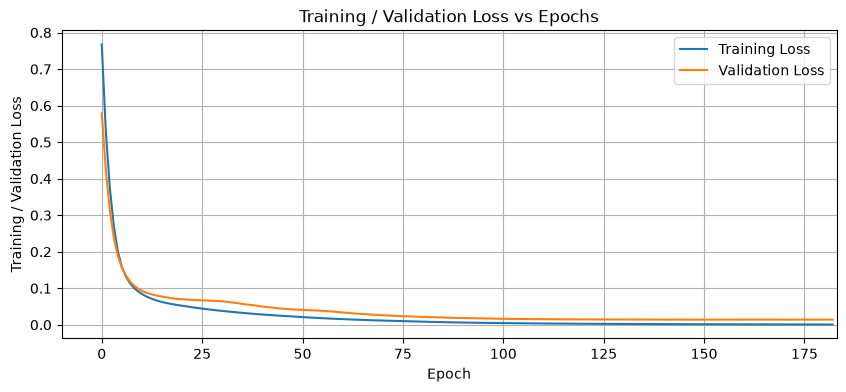

In [15]:
# Plot Training / Validation Loss vs Epochs

plt.figure(figsize = (10, 4))

plt.plot(range(len(model_loss)), model_loss['loss'], label = 'Training Loss')
plt.plot(range(len(model_loss)), model_loss['val_loss'], label = 'Validation Loss')

plt.xlim([-10, len(model_loss)])
plt.xlabel('Epoch')
plt.ylabel('Training / Validation Loss')
plt.title('Training / Validation Loss vs Epochs')
plt.legend()
plt.grid()

## Example Three: Adding in DropOut Layers

In [16]:
from tensorflow.keras.layers import Dropout                     # Import Dropout method

# Get information about the class
help(Dropout)

Help on class Dropout in module keras.src.layers.regularization.dropout:

class Dropout(keras.src.layers.layer.Layer)
 |  Dropout(rate, noise_shape=None, seed=None, **kwargs)
 |
 |  Applies dropout to the input.
 |
 |  The `Dropout` layer randomly sets input units to 0 with a frequency of
 |  `rate` at each step during training time, which helps prevent overfitting.
 |  Inputs not set to 0 are scaled up by `1 / (1 - rate)` such that the sum over
 |  all inputs is unchanged.
 |
 |  Note that the `Dropout` layer only applies when `training` is set to `True`
 |  in `call()`, such that no values are dropped during inference.
 |  When using `model.fit`, `training` will be appropriately set to `True`
 |  automatically. In other contexts, you can set the argument explicitly
 |  to `True` when calling the layer.
 |
 |  (This is in contrast to setting `trainable=False` for a `Dropout` layer.
 |  `trainable` does not affect the layer's behavior, as `Dropout` does
 |  not have any variables/weigh

In [ ]:
# we delete some neurons randomly at each iteration

# Train again the new model
model = Sequential()

model.add(Dense(units=30,activation='relu'))
model.add(Dropout(0.5))                                    # Add Dropout option to NN layers

model.add(Dense(units=15,activation='relu'))
model.add(Dropout(0.5))                                    # Add Dropout option to NN layers
  
model.add(Dense(units=1,activation='sigmoid'))
          
model.compile(loss='binary_crossentropy', optimizer='adam')

In [18]:
model.fit(x=X_train, y=y_train, epochs=600, validation_data=(X_test, y_test), verbose=1, callbacks=[early_stop])

Epoch 1/600
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - loss: 0.7705 - val_loss: 0.5038
Epoch 2/600
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.6150 - val_loss: 0.4193
Epoch 3/600
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.5246 - val_loss: 0.3640
Epoch 4/600
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.4419 - val_loss: 0.3209
Epoch 5/600
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.4738 - val_loss: 0.2850
Epoch 6/600
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.3748 - val_loss: 0.2600
Epoch 7/600
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.3184 - val_loss: 0.2369
Epoch 8/600
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.3165 - val_loss: 0.2162
Epoch 9/600
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.3215 - val_loss: 0.2001
Epoch 10/600
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.3011 - val_loss: 0.1862
Epoch 11/600
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.2894 - val_loss: 0.1722
Epoch 12/600
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (32, 30)               │           930 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (32, 30)               │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (32, 15)               │           465 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (32, 15)               │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (32, 1)                │            16 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,235 (16.55 KB)

 Trainable params: 1,411 (5.51 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,824 (11.04 KB)

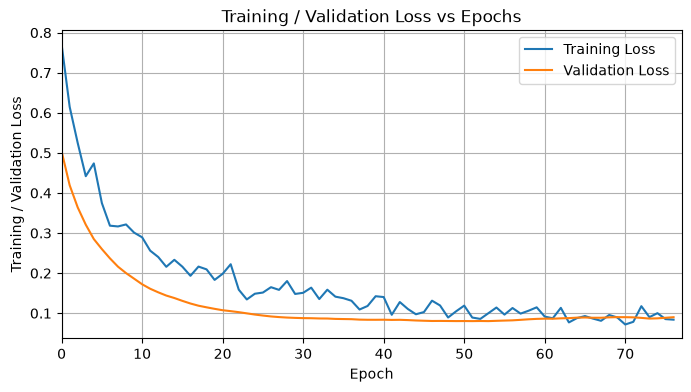

In [19]:
# Get information about model
model.summary()

# Save Training and Validation Loss in a Pandas DataFramemodel_loss.plot()
model_loss = pd.DataFrame(model.history.history)    

# Plot Training / Validation Loss vs Epochs
plt.figure(figsize = (8, 4))
plt.plot(range(len(model_loss)), model_loss['loss'], label = 'Training Loss')
plt.plot(range(len(model_loss)), model_loss['val_loss'], label = 'Validation Loss')
plt.xlim([0, len(model_loss)])
plt.xlabel('Epoch')
plt.ylabel('Training / Validation Loss')
plt.title('Training / Validation Loss vs Epochs')
plt.legend()
plt.grid()

# Model Evaluation

In [20]:
from sklearn.metrics import classification_report, confusion_matrix             # Import model evaluation Metrics

# Get predictions and set them to either 1 or 0
predictions = model.predict(X_test)
predictions = np.where(predictions > 0.5, 1, 0)

# Print results
print(classification_report(y_test, predictions))
print('Confusion matrix')
print(confusion_matrix(y_test, predictions))

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
              precision    recall  f1-score   support

           0       0.96      0.96      0.96        55
           1       0.98      0.98      0.98        88

    accuracy                           0.97       143
   macro avg       0.97      0.97      0.97       143
weighted avg       0.97      0.97      0.97       143

Confusion matrix
[[53  2]
 [ 2 86]]
